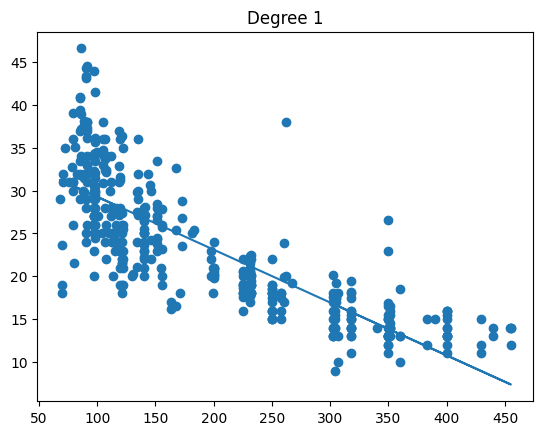

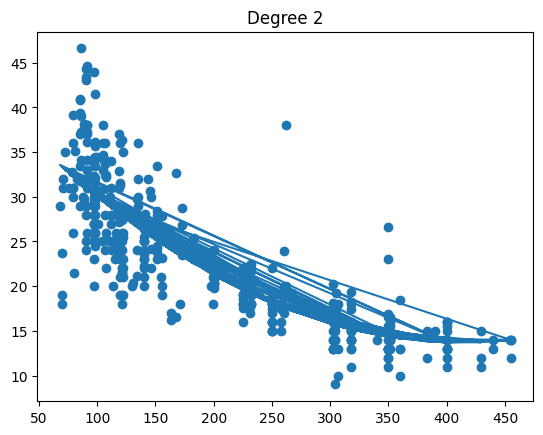

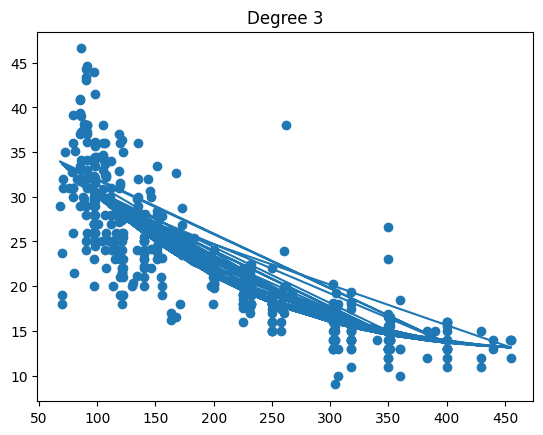

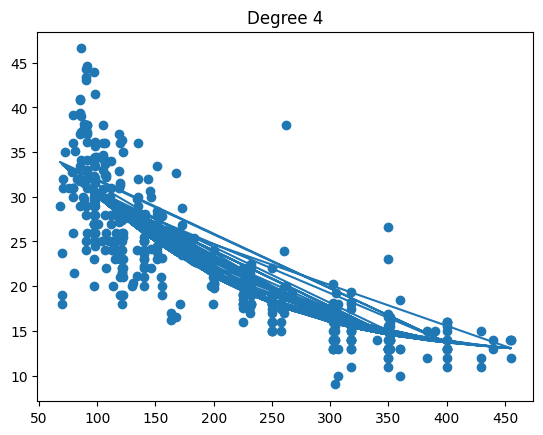

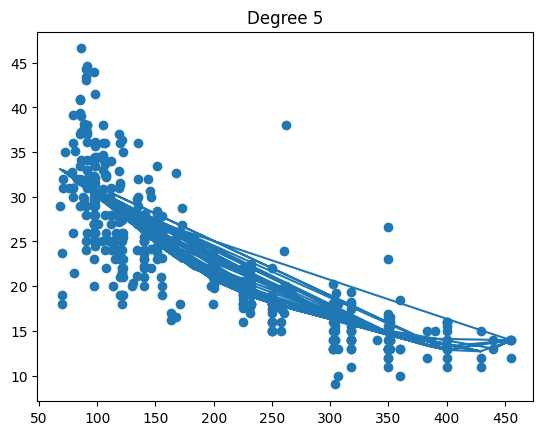

   Degree        MSE      RMSE        R2
0       1  18.102544  4.254708  0.663311
1       2  15.107354  3.886818  0.719019
2       3  14.943632  3.865699  0.722064
3       4  14.961487  3.868008  0.721732
4       5  15.230839  3.902671  0.716722


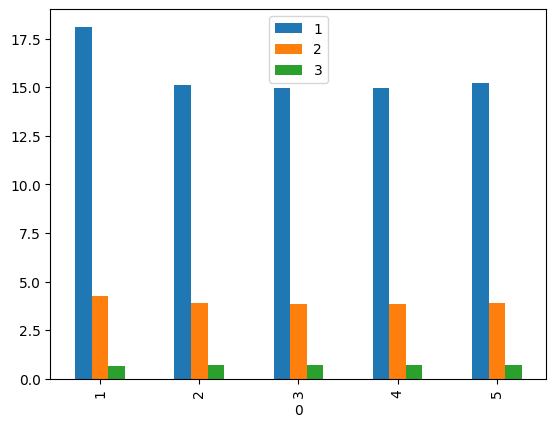

In [6]:
# Start
# Load Auto MPG dataset
# Remove missing values
# Select displacement as input and MPG as output
# Split data into training and testing sets
# Train Linear Regression and Polynomial Regression (degrees 2–5)
# Predict MPG using each model
# Calculate MSE, RMSE and R2 scores
# Compare model performance
# Plot regression curves and performance metrics
# Stop

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

df = sns.load_dataset('mpg')[['displacement', 'mpg']].dropna()
X = df[['displacement']]
y = df['mpg']
a, b, c, d = train_test_split(X, y, test_size=0.2, random_state=42)

R = []
for degree in range(1, 6):
    p = PolynomialFeatures(degree)
    A = p.fit_transform(a)
    B = p.transform(b)
    m = LinearRegression().fit(A, c)
    pred = m.predict(B)
    R.append([degree, mean_squared_error(d, pred),
              mean_squared_error(d, pred) ** 0.5, r2_score(d, pred)])

    plt.scatter(X, y)
    plt.plot(X, m.predict(p.transform(X)))
    plt.title(f'Degree {degree}')
    plt.show()

print(pd.DataFrame(R, columns=['Degree', 'MSE', 'RMSE', 'R2']))
pd.DataFrame(R).set_index(0).plot.bar()
plt.show()
